# VAE without conditioning

Este notebook organiza el VAE no condicionado. El modelo aprende la distribucion marginal de `X` y no recibe `C`, calendario, clima ni indicadores como entrada.

La ablation compara distintos valores de beta usando dos criterios de validación: menor validation loss y un criterio generativo basado en coverage, sharpness, RMSE y MMD. Test se usa solamente como análisis posterior.

## Setup

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd().resolve()
if current_dir.name == "notebooks" and current_dir.parent.name == "provincias":
    provinces_root = current_dir.parent
elif current_dir.name == "provincias":
    provinces_root = current_dir
elif (current_dir / "provincias").exists():
    provinces_root = current_dir / "provincias"
else:
    raise RuntimeError("No se pudo ubicar la carpeta provincias")

src_dir = provinces_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from model_utils import (
    evaluate_overall_generated_scenarios,
    list_generation_plot_paths,
    load_dates,
    load_result_table,
    load_x_scaler,
    load_x_splits,
    plot_latent_boxplot,
    plot_latent_kl,
    plot_metric_by_province,
    plot_month_metrics,
    plot_nrmse_by_province,
    plot_province_hour_heatmap,
    plot_real_reconstructed_prior_profiles,
    plot_training_history,
    print_split_checks,
    select_device,
    validate_x_splits,
)
from vae_without_conditioning import (
    beta_label,
    encode_distribution_array,
    generate_vae_scenarios,
    load_vae_checkpoint,
    reconstruct_array,
    run_vae_without_conditioning,
)

splits_dir = provinces_root / "data" / "splits"
output_dir = provinces_root / "results" / "vae_without_conditioning"
pretrained_vae_path = output_dir / "vae_best.pt"
if not pretrained_vae_path.exists():
    pretrained_vae_path = None

splits_dir, output_dir

(PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/data/splits'),
 PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/vae_without_conditioning'))

## Datos de entrada

El VAE usa solamente `X_train`, `X_val` y `X_test`. No usa condiciones como input.

In [2]:
X = load_x_splits(splits_dir)
validate_x_splits(X)
print_split_checks(X)

X_train: shape=(1457, 528), mean=0.0000, std=1.0000, nan_count=0
X_val: shape=(366, 528), mean=0.3081, std=1.1119, nan_count=0
X_test: shape=(485, 528), mean=0.4511, std=1.1791, nan_count=0


## Ejecutar o cargar resultados

In [3]:
RUN_ANALYSIS = False
RUN_BETA_ABLATION = False

config = SimpleNamespace(
    splits_dir=splits_dir,
    output_dir=output_dir,
    pretrained_vae_path=pretrained_vae_path,
    seed=42,
    device="auto",
    latent_dim=16,
    hidden_dim=256,
    epochs=200,
    batch_size=64,
    learning_rate=1e-3,
    weight_decay=1e-5,
    beta=0.01,
    beta_grid=[0.01, 0.05, 0.1, 1.0],
    beta_warmup_epochs=30,
    patience=25,
    min_delta=1e-5,
    n_scenarios=500,
    mmd_max_samples=1000,
    plot_days=4,
    run_beta_ablation=RUN_BETA_ABLATION,
)

if RUN_ANALYSIS or RUN_BETA_ABLATION:
    display(run_vae_without_conditioning(config))
else:
    print(f"Usando resultados guardados en {output_dir}")

Usando resultados guardados en /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/vae_without_conditioning


In [4]:
required_files = [
    output_dir / "config.json",
    output_dir / "training_history.csv",
    output_dir / "reconstruction_metrics.csv",
    output_dir / "metrics_overall.csv",
    output_dir / "metrics_by_month.csv",
    output_dir / "metrics_by_province.csv",
    output_dir / "coverage_by_province_hour.csv",
    output_dir / "rmse_by_province_hour.csv",
    output_dir / "latent_kl_by_dimension.csv",
    output_dir / "vae_beta_ablation.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Faltan resultados. Cambiar RUN_ANALYSIS/RUN_BETA_ABLATION a True. Archivos: {missing_files}")

## Entrenamiento base

Con beta bajo, el VAE suele reconstruir mejor, pero puede quedar menos alineado con el prior normal usado para generar muestras.

,value
batch_size,64
beta,0.01
beta_warmup_epochs,30
data_source,/Users/victoriapersico/Desktop/Ingenieria/Terc...
device,cpu
epochs,200
hidden_dim,256
latent_dim,16
learning_rate,0.001
model,vae_without_conditioning


,split,reconstruction_mse_scaled
0,train,0.043494
1,val,0.104020
2,test,0.152926


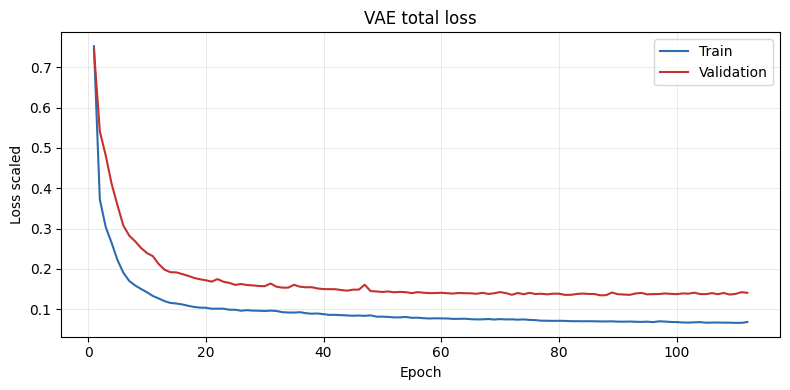

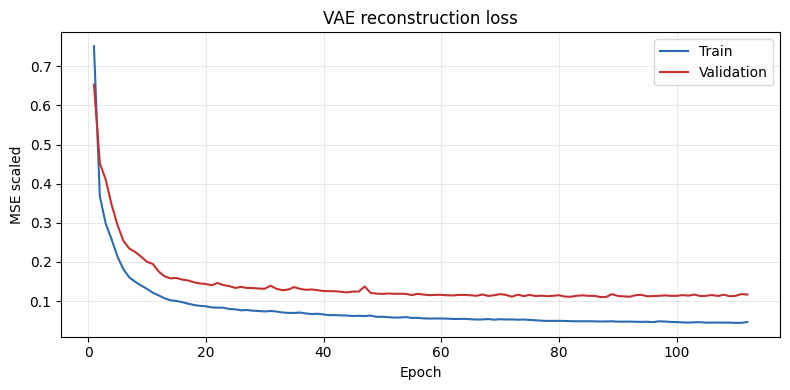

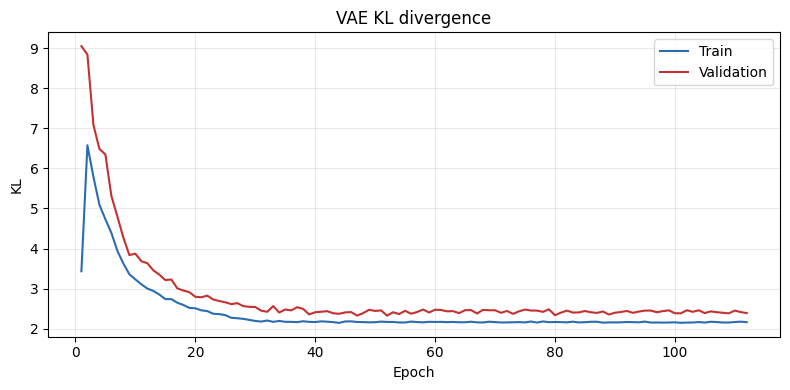

In [5]:
with open(output_dir / "config.json", "r", encoding="utf-8") as file:
    saved_config = json.load(file)

history = load_result_table(output_dir, "training_history.csv")
reconstruction_metrics = load_result_table(output_dir, "reconstruction_metrics.csv")
display(pd.Series(saved_config, name="value").to_frame())
display(reconstruction_metrics)
plot_training_history(history, "train_total", "val_total", "VAE total loss", "Loss scaled")
plot_training_history(history, "train_reconstruction", "val_reconstruction", "VAE reconstruction loss", "MSE scaled")
plot_training_history(history, "train_kl", "val_kl", "VAE KL divergence", "KL")

## Ablation de beta

La tabla prueba `beta = [0.01, 0.05, 0.1, 1.0]`. Cada beta se entrena con `X_train`, se valida con `X_val` y despues se evalua en test. Se reportan dos selecciones hechas solo con validation: menor `val_total_loss` y criterio generativo por cercania a coverage 0.90, menor sharpness, menor RMSE del perfil medio y menor MMD.

,beta,val_reconstruction_loss,val_kl_loss,val_total_loss,val_coverage,val_sharpness,val_rmse_mean_profile,val_mmd,val_coverage_gap,test_reconstruction_loss,test_kl_loss,test_total_loss,test_coverage,test_sharpness,test_rmse_mean_profile,test_mmd,mean_kl,active_latent_dimensions
0,0.01,0.110413,2.394311,0.134356,0.649999,251.929566,297.518860,0.053229,0.250001,0.155089,2.735955,0.182449,0.621704,252.093052,308.647125,0.064780,2.733665,16
1,0.05,0.146819,1.190348,0.206337,0.749845,314.650500,298.862518,0.020781,0.150155,0.199386,1.312193,0.264996,0.717167,314.544242,308.371979,0.025065,1.310057,16
2,0.10,0.176961,0.843822,0.261343,0.767987,327.142803,298.855316,0.018403,0.132013,0.239397,0.924420,0.331839,0.734149,327.526283,308.307587,0.020921,0.922600,15
3,1.00,0.422581,0.195268,0.617848,0.746393,329.231352,298.477966,0.023304,0.153607,0.541901,0.197713,0.739614,0.719787,329.689501,309.140045,0.019837,0.198326,4


,selection_criterion,beta,val_reconstruction_loss,val_kl_loss,val_total_loss,val_coverage,val_sharpness,val_rmse_mean_profile,val_mmd,val_coverage_gap,test_reconstruction_loss,test_kl_loss,test_total_loss,test_coverage,test_sharpness,test_rmse_mean_profile,test_mmd,mean_kl,active_latent_dimensions
0,validation_total_loss,0.01,0.110413,2.394311,0.134356,0.649999,251.929566,297.518860,0.053229,0.250001,0.155089,2.735955,0.182449,0.621704,252.093052,308.647125,0.064780,2.733665,16
1,validation_generative,0.10,0.176961,0.843822,0.261343,0.767987,327.142803,298.855316,0.018403,0.132013,0.239397,0.924420,0.331839,0.734149,327.526283,308.307587,0.020921,0.922600,15


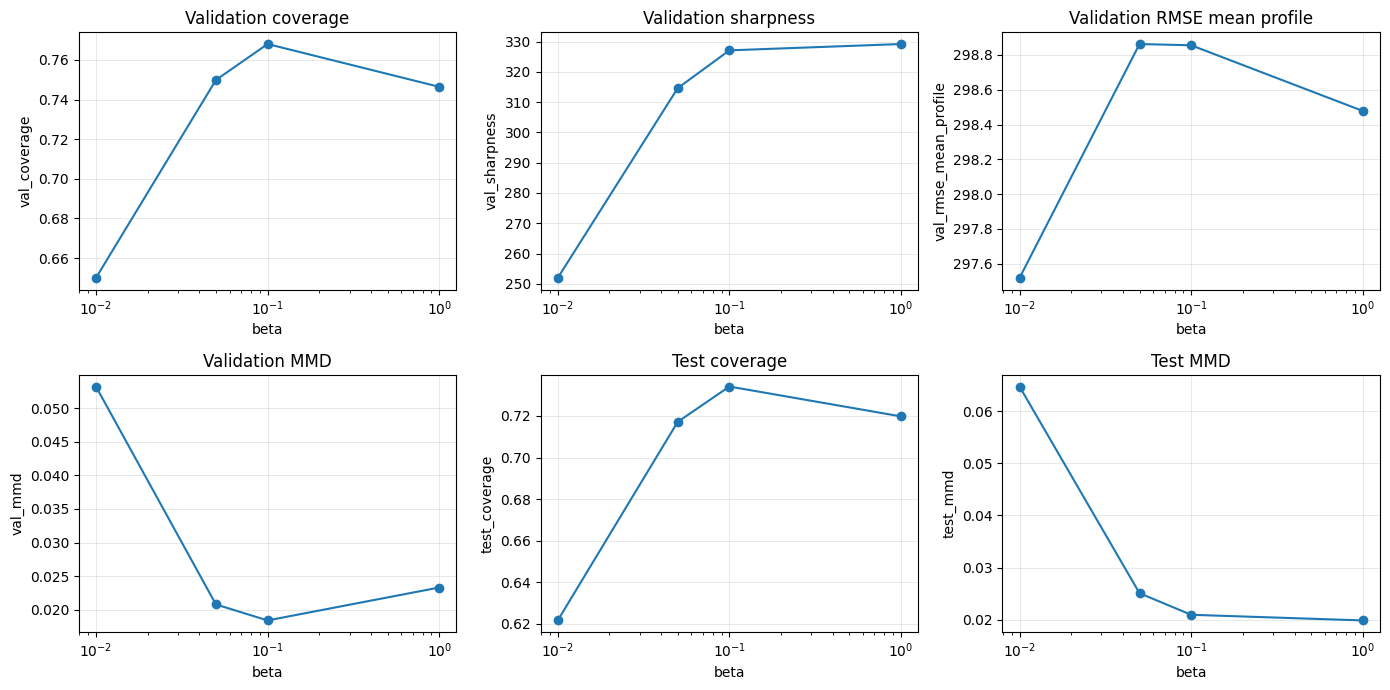

In [6]:
def compute_validation_generation_metrics(
    beta_values: list[float],
    output_dir: Path,
    X_val: np.ndarray,
    x_scaler: object,
    config: SimpleNamespace,
) -> pd.DataFrame:
    """Evaluate prior samples from each beta model on the validation split."""
    device = select_device(config.device)
    rows = []
    ablation_model_dir = output_dir / "beta_ablation_models"
    for beta in beta_values:
        model_path = ablation_model_dir / f"vae_beta_{beta_label(float(beta))}.pt"
        if not model_path.exists():
            raise FileNotFoundError(f"Falta el modelo entrenado para beta={beta}: {model_path}")
        model, _ = load_vae_checkpoint(model_path, device)
        generated_val = generate_vae_scenarios(
            model=model,
            n_days=len(X_val),
            n_scenarios=config.n_scenarios,
            seed=config.seed,
            device=device,
            batch_size=config.batch_size,
        )
        metrics = evaluate_overall_generated_scenarios(
            real_scaled=X_val,
            generated_scaled=generated_val,
            scaler=x_scaler,
            seed=config.seed,
            mmd_max_samples=config.mmd_max_samples,
        ).iloc[0]
        rows.append(
            {
                "beta": float(beta),
                "val_coverage": float(metrics["coverage_p5_p95"]),
                "val_sharpness": float(metrics["sharpness_p5_p95_mwh"]),
                "val_rmse_mean_profile": float(metrics["mean_profile_rmse_mwh"]),
                "val_mmd": float(metrics["mmd_rbf"]),
            }
        )
    return pd.DataFrame(rows)


def complete_beta_ablation_table(
    beta_ablation: pd.DataFrame,
    validation_metrics: pd.DataFrame,
) -> pd.DataFrame:
    """Merge validation generative metrics into the beta ablation table."""
    preserved_columns = [
        "beta",
        "val_reconstruction_loss",
        "val_kl_loss",
        "val_total_loss",
        "val_coverage",
        "val_sharpness",
        "val_rmse_mean_profile",
        "val_mmd",
        "val_coverage_gap",
        "test_reconstruction_loss",
        "test_kl_loss",
        "test_total_loss",
        "test_coverage",
        "test_sharpness",
        "test_rmse_mean_profile",
        "test_mmd",
        "mean_kl",
        "active_latent_dimensions",
    ]
    clean_ablation = beta_ablation.drop(
        columns=[
            "val_coverage",
            "val_sharpness",
            "val_rmse_mean_profile",
            "val_mmd",
            "val_coverage_gap",
        ],
        errors="ignore",
    )
    completed = clean_ablation.merge(validation_metrics, on="beta", how="left")
    completed["val_coverage_gap"] = (completed["val_coverage"] - 0.90).abs()
    return completed[preserved_columns].sort_values("beta").reset_index(drop=True)


def build_beta_selection_comparison(beta_ablation: pd.DataFrame) -> pd.DataFrame:
    """Select beta by validation loss and by validation generative metrics."""
    loss_row = beta_ablation.sort_values("val_total_loss", ascending=True).iloc[0].to_dict()
    generative_row = (
        beta_ablation.sort_values(
            ["val_coverage_gap", "val_sharpness", "val_rmse_mean_profile", "val_mmd"],
            ascending=[True, True, True, True],
        )
        .iloc[0]
        .to_dict()
    )
    rows = []
    for criterion, row in [
        ("validation_total_loss", loss_row),
        ("validation_generative", generative_row),
    ]:
        selected = {"selection_criterion": criterion}
        selected.update(row)
        rows.append(selected)
    columns = [
        "selection_criterion",
        "beta",
        "val_reconstruction_loss",
        "val_kl_loss",
        "val_total_loss",
        "val_coverage",
        "val_sharpness",
        "val_rmse_mean_profile",
        "val_mmd",
        "val_coverage_gap",
        "test_reconstruction_loss",
        "test_kl_loss",
        "test_total_loss",
        "test_coverage",
        "test_sharpness",
        "test_rmse_mean_profile",
        "test_mmd",
        "mean_kl",
        "active_latent_dimensions",
    ]
    comparison = pd.DataFrame(rows)[columns]
    comparison["active_latent_dimensions"] = comparison["active_latent_dimensions"].astype(int)
    return comparison


beta_ablation = load_result_table(output_dir, "vae_beta_ablation.csv")
x_scaler = load_x_scaler(splits_dir)
validation_metrics = compute_validation_generation_metrics(
    beta_values=config.beta_grid,
    output_dir=output_dir,
    X_val=X["val"],
    x_scaler=x_scaler,
    config=config,
)
beta_ablation = complete_beta_ablation_table(beta_ablation, validation_metrics)
beta_selection_comparison = build_beta_selection_comparison(beta_ablation)

beta_ablation.to_csv(output_dir / "vae_beta_ablation.csv", index=False)
beta_selection_comparison.to_csv(output_dir / "vae_beta_selection_comparison.csv", index=False)

display(beta_ablation)
display(beta_selection_comparison)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
plots = [
    ("val_coverage", "Validation coverage"),
    ("val_sharpness", "Validation sharpness"),
    ("val_rmse_mean_profile", "Validation RMSE mean profile"),
    ("val_mmd", "Validation MMD"),
    ("test_coverage", "Test coverage"),
    ("test_mmd", "Test MMD"),
]
for ax, (column, title) in zip(axes.ravel(), plots):
    ax.plot(beta_ablation["beta"], beta_ablation[column], marker="o")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("beta")
    ax.set_ylabel(column)
    ax.grid(linewidth=0.4, alpha=0.5)
fig.tight_layout()
plt.show()

El beta con menor `val_total_loss` no necesariamente es el mejor generativamente, porque cada beta cambia el peso del termino KL en la funcion objetivo. Beta bajo suele favorecer reconstruccion, pero puede samplear peor desde el prior `N(0, I)`. Beta mas alto puede empeorar reconstruccion y aun asi mejorar coverage o MMD si alinea mejor el posterior con el prior. La seleccion por `val_total_loss` responde al objetivo de entrenamiento; la seleccion generativa por validation esta mas alineada con producir escenarios plausibles. Test queda solamente como reporte final y no se usa para elegir beta. El VAE sigue siendo no condicionado: no recibe clima, calendario ni indicadores, y no genera escenarios adaptados a un dia especifico.

# Las métricas detalladas por mes, provincia y hora corresponden al modelo base entrenado con beta = 0.01. La comparación entre betas se reporta en la sección de ablation.

## Evaluacion final del modelo base

In [7]:
overall_metrics = load_result_table(output_dir, "metrics_overall.csv")
display(overall_metrics.T.rename(columns={0: "value"}))

row = overall_metrics.iloc[0]
print(f"Coverage P5-P95: {row['coverage_p5_p95']:.3f}")
print(f"Sharpness promedio P5-P95: {row['sharpness_p5_p95_mwh']:.2f} MWh")
print(f"RMSE del perfil medio: {row['mean_profile_rmse_mwh']:.2f} MWh")
print(f"MMD RBF: {row['mmd_rbf']:.6f}")

,value
coverage_p5_p95,0.621704
sharpness_p5_p95_mwh,252.093052
mean_profile_rmse_mwh,308.647125
mmd_rbf,0.064780
n_days,485.000000
n_scenarios_per_day,500.000000


Coverage P5-P95: 0.622
Sharpness promedio P5-P95: 252.09 MWh
RMSE del perfil medio: 308.65 MWh
MMD RBF: 0.064780


## Evaluacion por mes, provincia y hora

,mes,coverage,sharpness,rmse_mean_profile,n_days
0,1,0.391832,252.078470,359.284149,62
1,2,0.388122,252.304057,332.940186,56
2,3,0.671524,252.477738,292.641052,62
3,4,0.717393,251.321572,231.211090,60
4,5,0.711755,252.521894,259.664093,31
5,6,0.704798,251.713683,416.484802,30
6,7,0.664223,253.231801,401.632721,31
7,8,0.784152,251.485699,251.000916,31
8,9,0.760101,252.185929,216.154831,30
9,10,0.765640,251.481938,233.901047,31


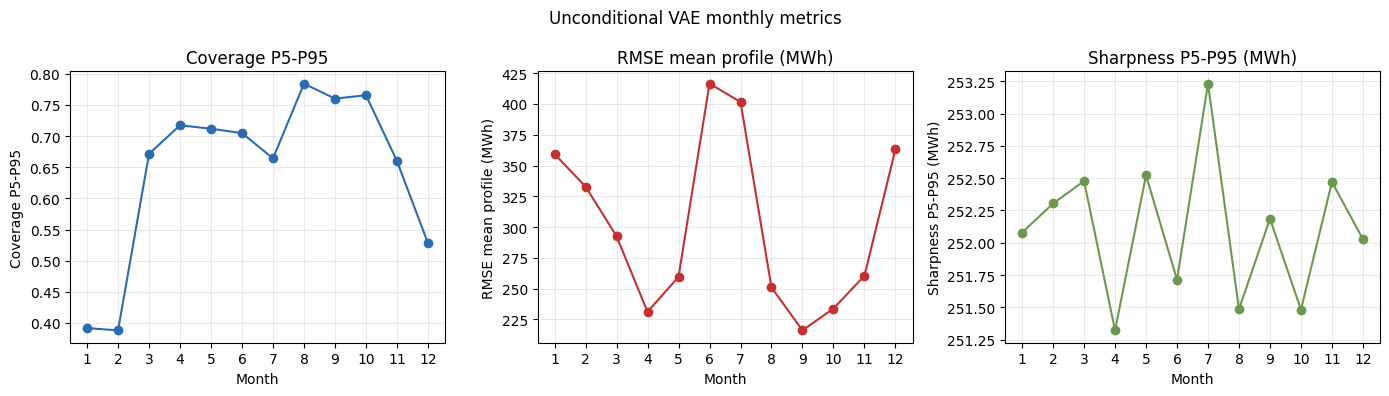

,province,rmse,mean_profile_rmse_mwh,mean_demand,mean_demand_mwh,nrmse,coverage,coverage_p5_p95,sharpness,sharpness_p5_p95_mwh,mmd_rbf
20,sgo_del_estero,95.503723,95.503723,241.469025,241.469025,0.395511,0.617869,0.617869,120.835197,120.835197,0.132489
2,chaco,149.016510,149.016510,401.316223,401.316223,0.371319,0.605670,0.605670,210.386022,210.386022,0.143749
7,formosa,66.653069,66.653069,184.996826,184.996826,0.360293,0.568900,0.568900,105.953958,105.953958,0.150596
5,corrientes,118.451164,118.451164,375.334198,375.334198,0.315589,0.576460,0.576460,161.581478,161.581478,0.143523
16,san_juan,78.292343,78.292343,285.251984,285.251984,0.274467,0.571134,0.571134,116.330792,116.330792,0.115552
21,tucuman,95.581940,95.581940,392.474487,392.474487,0.243537,0.656615,0.656615,138.975804,138.975804,0.074802
10,la_rioja,43.872242,43.872242,186.800217,186.800217,0.234862,0.589433,0.589433,65.549053,65.549053,0.106761
9,la_pampa,25.417591,25.417591,108.317688,108.317688,0.234658,0.663574,0.663574,33.370114,33.370114,0.070122


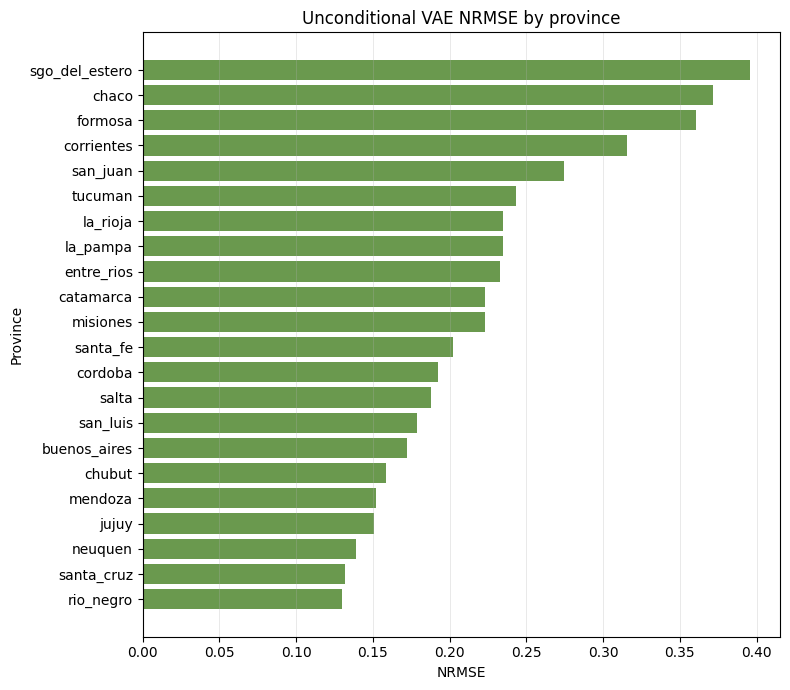

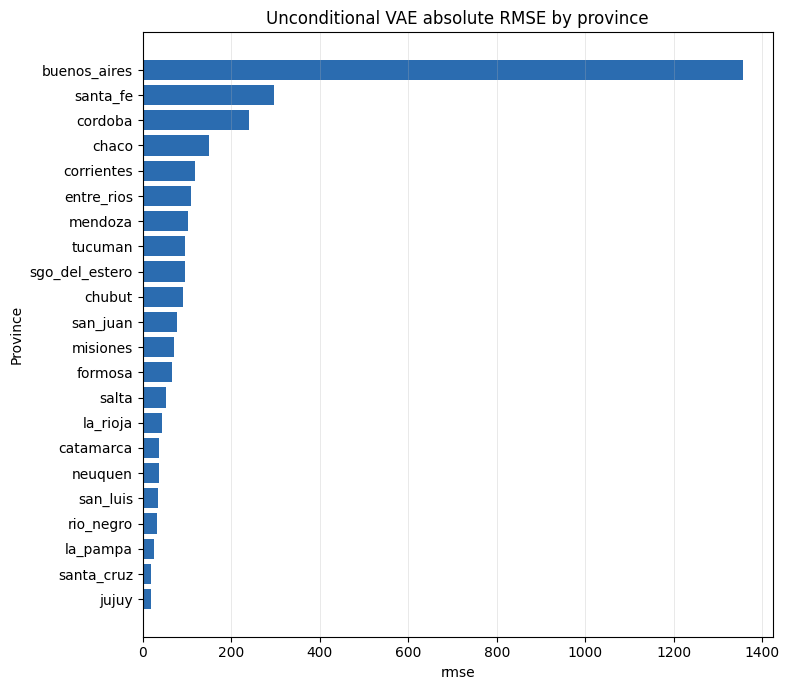

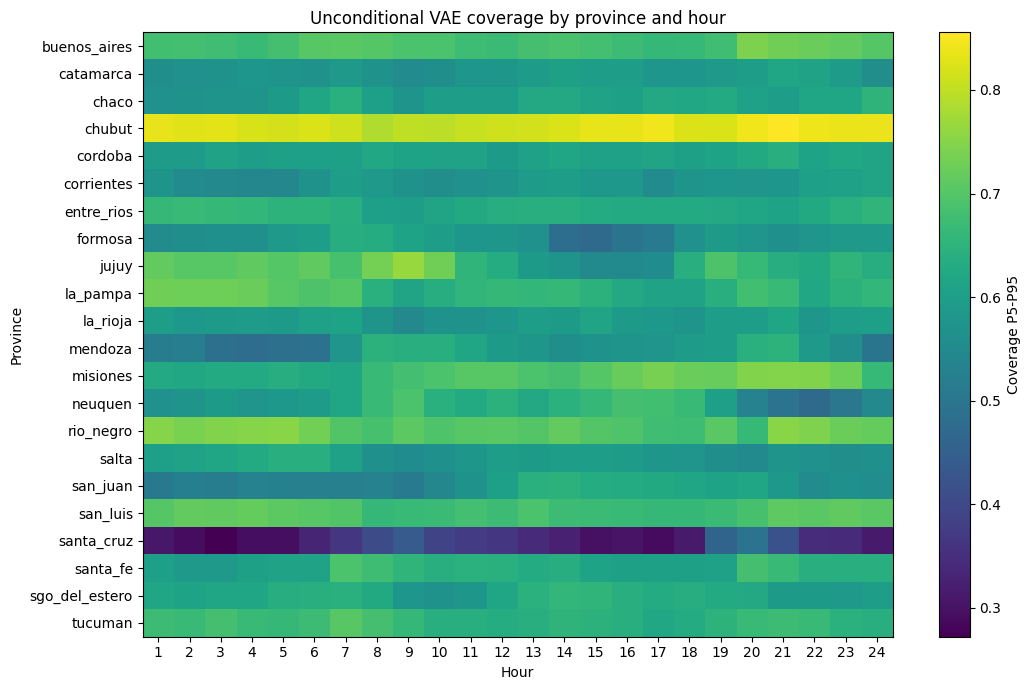

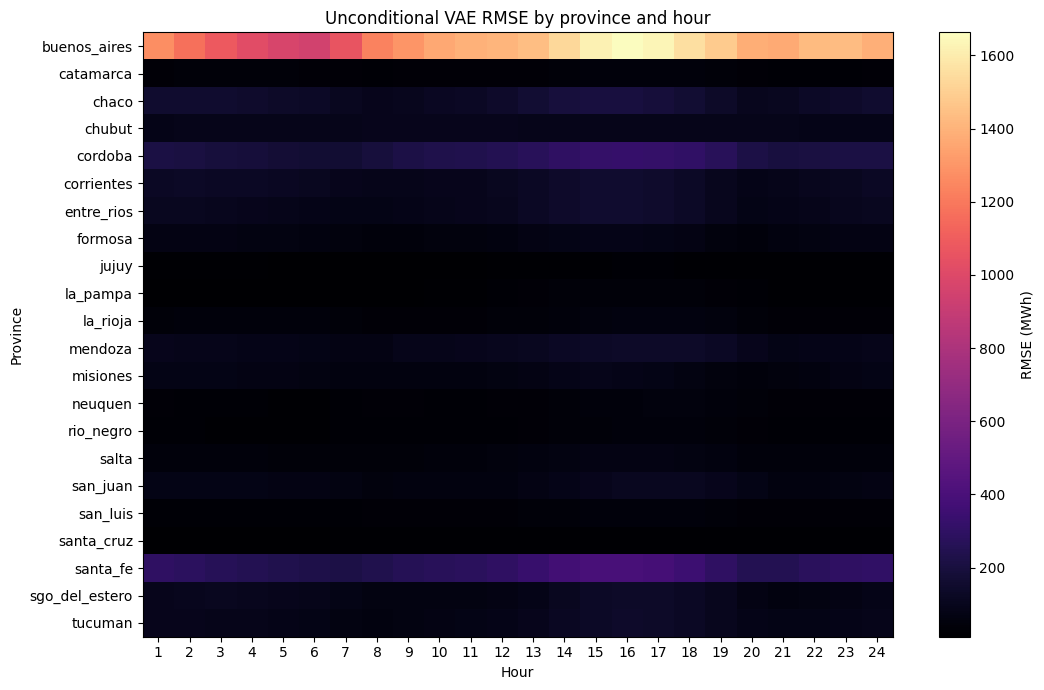

In [8]:
metrics_by_month = load_result_table(output_dir, "metrics_by_month.csv")
province_metrics = load_result_table(output_dir, "metrics_by_province.csv")
coverage_by_hour = pd.read_csv(output_dir / "coverage_by_province_hour.csv", index_col=0)
rmse_by_hour = pd.read_csv(output_dir / "rmse_by_province_hour.csv", index_col=0)

display(metrics_by_month)
plot_month_metrics(metrics_by_month, "Unconditional VAE monthly metrics")
display(province_metrics.sort_values("nrmse", ascending=False).head(8))
plot_nrmse_by_province(province_metrics, "Unconditional VAE NRMSE by province")
plot_metric_by_province(province_metrics, "rmse", "Unconditional VAE absolute RMSE by province")
plot_province_hour_heatmap(coverage_by_hour, "Unconditional VAE coverage by province and hour", "Coverage P5-P95", "viridis")
plot_province_hour_heatmap(rmse_by_hour, "Unconditional VAE RMSE by province and hour", "RMSE (MWh)", "magma")

## Diagnostico del espacio latente

,latent_dim,mu_mean,mu_std,logvar_mean,std_mean,kl
0,1,-0.210832,0.884089,-3.480281,0.180777,1.670462
1,2,-0.048770,1.280058,-4.147579,0.130314,2.403353
2,3,-0.127083,1.186316,-5.797093,0.058459,3.112230
3,4,0.543394,1.040073,-4.261482,0.122812,2.327344
4,5,0.080575,0.889088,-3.598490,0.169636,1.712846
5,6,-0.233034,0.804372,-3.826465,0.152501,1.776311
6,7,-0.349788,1.780712,-5.324850,0.075615,3.812353
7,8,-0.564061,1.163883,-3.790166,0.156999,2.244728
8,9,0.791064,1.452880,-4.291880,0.122174,3.022327
9,10,-0.751390,1.352080,-5.184952,0.079565,3.292450


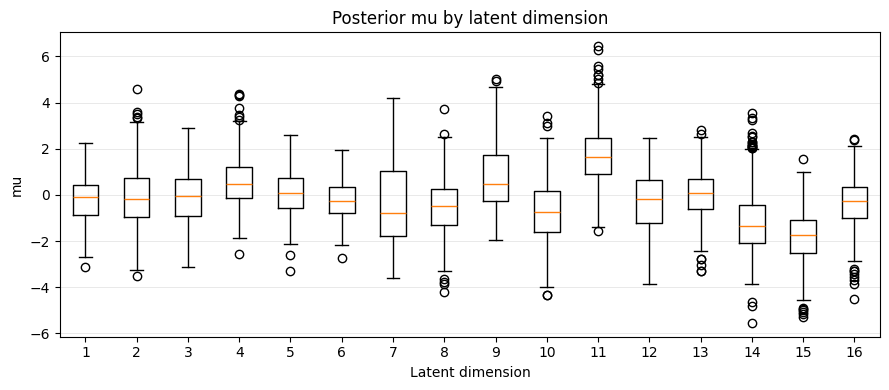

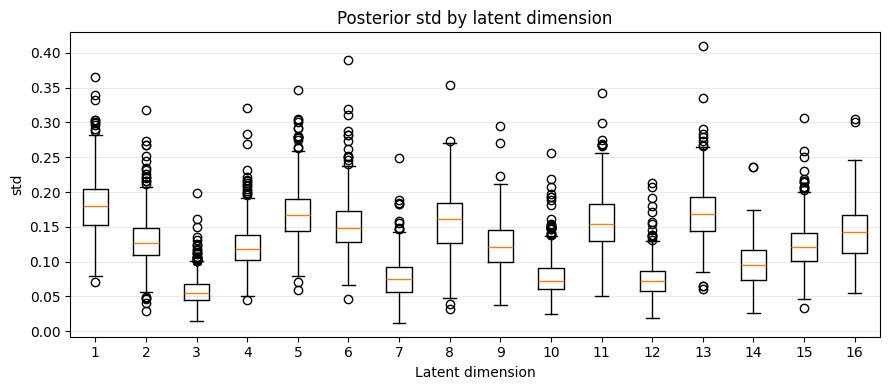

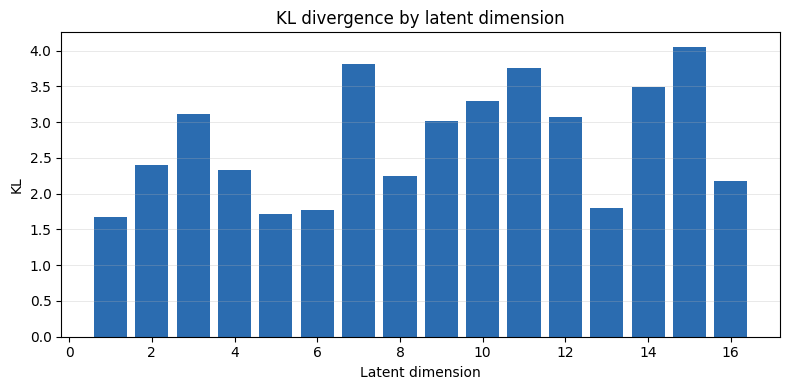

Dimensiones activas con KL > 0.01: 16 de 16


In [9]:
device = select_device("auto")
model, checkpoint = load_vae_checkpoint(output_dir / "vae_best.pt", device)
mu_test, logvar_test = encode_distribution_array(model, X["test"], device, batch_size=64)
std_test = np.exp(0.5 * logvar_test)
latent_kl = load_result_table(output_dir, "latent_kl_by_dimension.csv")

display(latent_kl)
plot_latent_boxplot(mu_test, "Posterior mu by latent dimension", "mu")
plot_latent_boxplot(std_test, "Posterior std by latent dimension", "std")
plot_latent_kl(latent_kl)
active_dims = int((latent_kl["kl"] > 0.01).sum())
print(f"Dimensiones activas con KL > 0.01: {active_dims} de {len(latent_kl)}")

## Reconstrucciones vs muestras del prior

Una buena reconstruccion no garantiza buenas muestras generativas si el posterior aprendido no coincide bien con el prior.

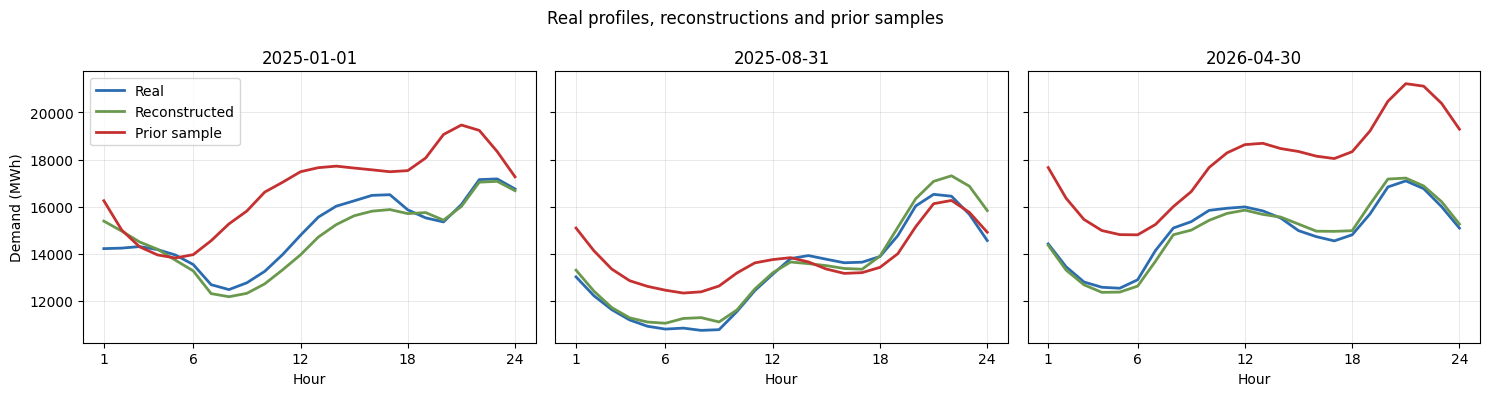

In [10]:
dates_test = load_dates(splits_dir, "test")
x_scaler = load_x_scaler(splits_dir)
selected_indices = np.linspace(0, len(X["test"]) - 1, num=3, dtype=int)
real_sample = X["test"][selected_indices]
reconstructed_sample = reconstruct_array(model, real_sample, device, batch_size=64)
prior_sample = generate_vae_scenarios(model, len(selected_indices), 1, 42, device, 64).reshape(len(selected_indices), -1)
plot_real_reconstructed_prior_profiles(real_sample, reconstructed_sample, prior_sample, x_scaler, dates_test[selected_indices])

## Perfiles reales vs generados

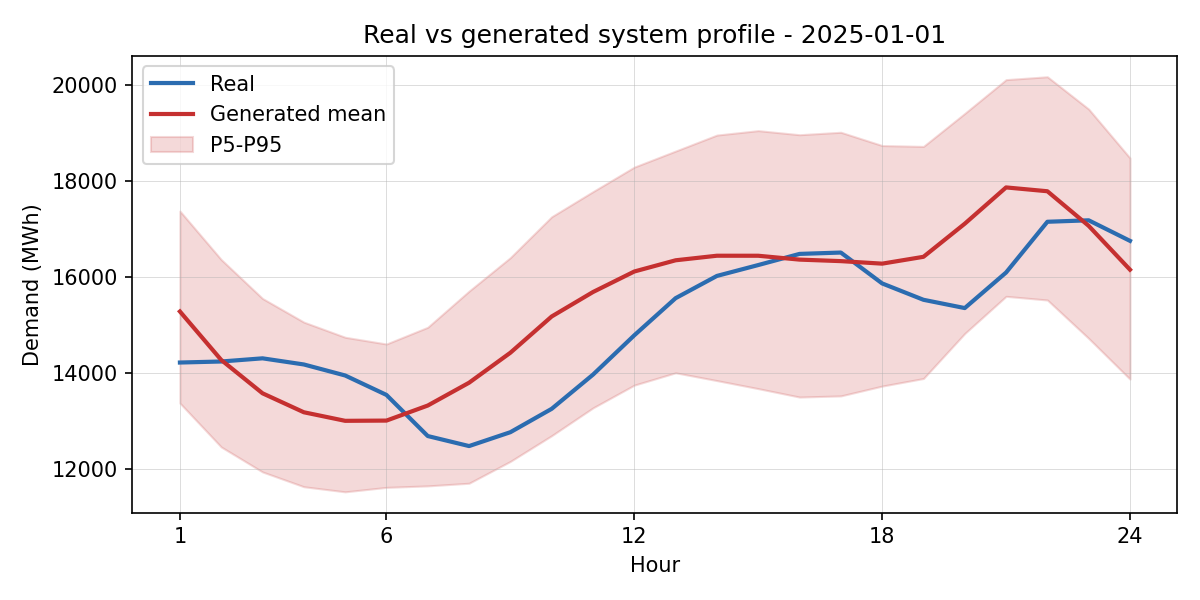

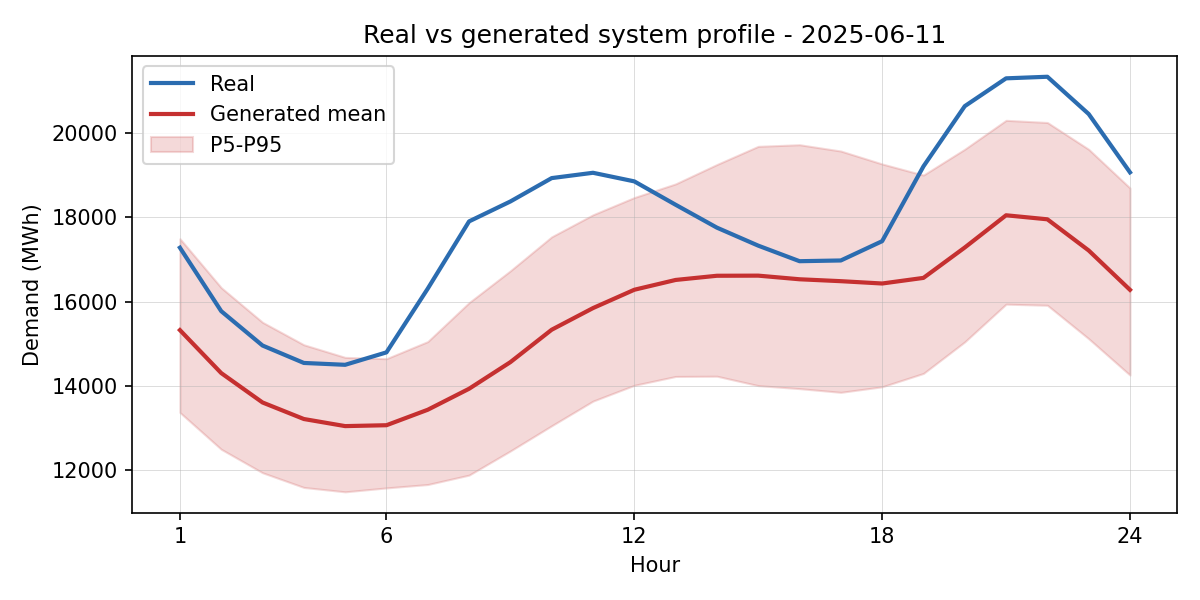

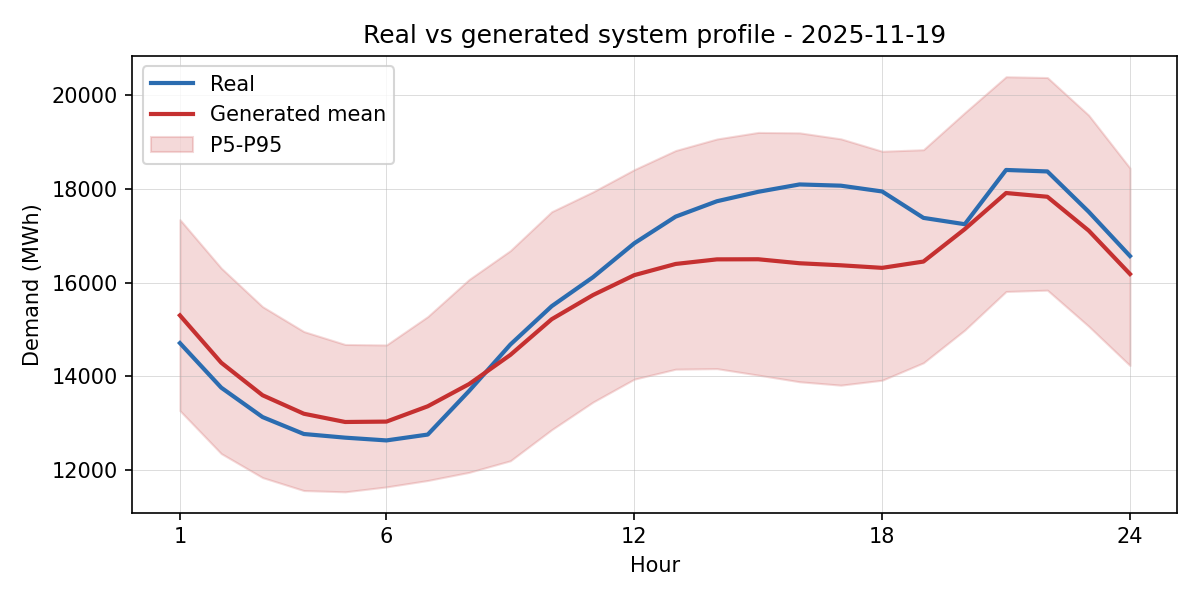

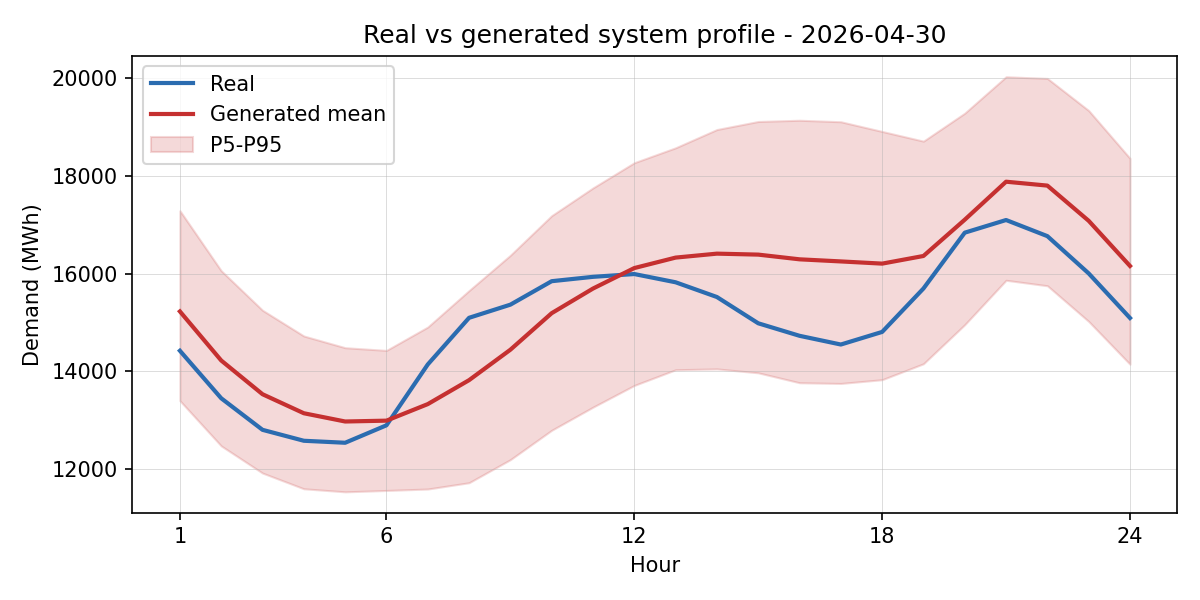

In [11]:
for plot_path in list_generation_plot_paths(output_dir, max_plots=4):
    display(Image(filename=str(plot_path)))

## Conclusion

La ablation muestra el trade-off de beta desde dos lecturas de validation. El criterio por `val_total_loss` resume calidad reconstructiva y objetivo de entrenamiento, mientras que el criterio generativo prioriza escenarios con coverage cercano a 0.90, bandas mas informativas, menor error del perfil medio y menor MMD. Test se reporta despues para comparar los betas seleccionados, pero no participa en la decision. Este VAE sigue siendo una ablation marginal: no conoce calendario, clima ni indicadores, por lo que el CVAE deberia mejorar al generar escenarios condicionados al contexto del dia.